In [1]:
# Run once. Comment out if already installed.
!pip install -q librosa soundfile scikit-learn scipy matplotlib seaborn tqdm joblib
# Only needed if USE_ASR = True:
# !pip install -q faster-whisper sentence-transformers


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, glob, json, re, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
from joblib import Parallel, delayed
import librosa
warnings.filterwarnings("ignore")

# ------------------------- CONFIG (edit these) -------------------------
DATA_DIR    = "Dataset_Final"          # folder with the csv files and .wav files (searched recursively)
CACHE_DIR   = "cache_lite" # computed features are cached here, so re-runs are instant
SR          = 16000        # sample rate used for loading (lower = faster)
MAX_SECONDS = 60           # audio longer than this is cut
N_JOBS      = -1           # -1 = use all CPU cores
USE_ASR     = False        # True = add tiny.en transcription (slower, usually better)
ASR_SECONDS = 30           # only the first N seconds are transcribed (saves time)
N_FOLDS     = 5
SEED        = 42
# -----------------------------------------------------------------------
os.makedirs(CACHE_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("CPU cores:", os.cpu_count())

CPU cores: 4


C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test  = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sub   = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
FILE_COL, LABEL_COL = train.columns[0], train.columns[1]   # first col = file name, second = grammar score
print("train columns:", list(train.columns), "| test:", list(test.columns), "| submission:", list(sub.columns))

wav_index = {os.path.basename(p): p for p in glob.glob(os.path.join(DATA_DIR, "**", "*.wav"), recursive=True)}
print("wav files found:", len(wav_index))

def resolve(name):
    name = str(name)
    for cand in (name, name + ".wav"):
        if cand in wav_index: return wav_index[cand]
    raise FileNotFoundError(f"Audio for {name} not found under {DATA_DIR}")

train["path"] = train[FILE_COL].map(resolve)
test["path"]  = test[FILE_COL].map(resolve)
y = train[LABEL_COL].astype(float).values
all_df = pd.concat([train.assign(split="train"), test.assign(split="test")], ignore_index=True)
is_tr = (all_df["split"] == "train").values
print(train.shape, test.shape)

train columns: ['filename', 'label'] | test: ['filename', 'label'] | submission: ['filename', 'label']
wav files found: 773
(769, 3) (216, 3)


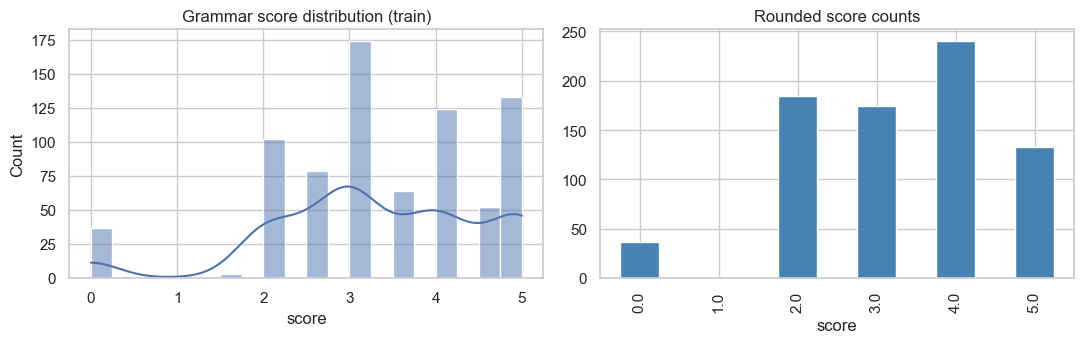

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
dtype: float64


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(y, bins=20, kde=True, ax=ax[0]); ax[0].set_title("Grammar score distribution (train)"); ax[0].set_xlabel("score")
pd.Series(y).round().value_counts().sort_index().plot(kind="bar", ax=ax[1], color="steelblue")
ax[1].set_title("Rounded score counts"); ax[1].set_xlabel("score")
plt.tight_layout(); plt.show()
print(pd.Series(y).describe())

In [5]:
def _stats(prefix, a):
    a = np.asarray(a, dtype=float)
    if a.size == 0: a = np.zeros(1)
    return {f"{prefix}_mean": a.mean(), f"{prefix}_std": a.std()}

def audio_features(path):
    """Extract ~100 cheap features from one audio file."""
    sig, sr = librosa.load(path, sr=SR, mono=True, duration=MAX_SECONDS)
    dur = len(sig) / sr
    f = {"dur": dur}
    hop = 256
    # --- MFCC + delta (timbre / articulation) ---
    mfcc = librosa.feature.mfcc(y=sig, sr=sr, n_mfcc=20, n_fft=512, hop_length=hop)
    dmf = librosa.feature.delta(mfcc)
    for i in range(20):
        f[f"mfcc{i}_mean"] = mfcc[i].mean(); f[f"mfcc{i}_std"] = mfcc[i].std(); f[f"dmfcc{i}_std"] = dmf[i].std()
    # --- spectral / energy ---
    S = np.abs(librosa.stft(sig, n_fft=512, hop_length=hop))
    for name, v in {"centroid": librosa.feature.spectral_centroid(S=S, sr=sr)[0],
                    "rolloff": librosa.feature.spectral_rolloff(S=S, sr=sr)[0],
                    "bandwidth": librosa.feature.spectral_bandwidth(S=S, sr=sr)[0],
                    "flatness": librosa.feature.spectral_flatness(S=S)[0],
                    "zcr": librosa.feature.zero_crossing_rate(sig, frame_length=512, hop_length=hop)[0],
                    "rms": librosa.feature.rms(y=sig, frame_length=512, hop_length=hop)[0]}.items():
        f.update(_stats(name, v))
    # --- pitch (YIN is much faster than pYIN) ---
    f0 = librosa.yin(sig, fmin=70, fmax=400, sr=sr, frame_length=1024, hop_length=512)
    rms512 = librosa.feature.rms(y=sig, frame_length=1024, hop_length=512)[0]
    n = min(len(f0), len(rms512)); f0, rms512 = f0[:n], rms512[:n]
    voiced = (rms512 > 0.1 * rms512.mean()) & (f0 > 75) & (f0 < 390)
    fv = f0[voiced] if voiced.any() else np.zeros(1)
    f.update({"f0_mean": fv.mean(), "f0_std": fv.std(), "f0_range": np.percentile(fv, 95) - np.percentile(fv, 5),
              "voiced_ratio": voiced.mean()})
    # --- pauses / fluency from silence segmentation ---
    iv = librosa.effects.split(sig, top_db=30, frame_length=1024, hop_length=hop)
    seg = (iv[:, 1] - iv[:, 0]) / sr if len(iv) else np.zeros(1)
    gaps = (iv[1:, 0] - iv[:-1, 1]) / sr if len(iv) > 1 else np.zeros(1)
    f.update({"n_segs": len(iv), "segs_per_sec": len(iv) / dur, "seg_mean": seg.mean(), "seg_std": seg.std(), "seg_max": seg.max(),
              "speech_ratio": seg.sum() / dur, "gap_mean": gaps.mean(), "gap_std": gaps.std(), "gap_max": gaps.max(),
              "n_gap_03": int((gaps > 0.3).sum()), "n_gap_06": int((gaps > 0.6).sum()), "n_gap_1": int((gaps > 1.0).sum()),
              "gap_ratio_03": gaps[gaps > 0.3].sum() / dur})
    # --- speaking-rate proxy via onsets ---
    on = librosa.onset.onset_detect(y=sig, sr=sr, hop_length=hop)
    f["onset_rate"] = len(on) / dur
    oenv = librosa.onset.onset_strength(y=sig, sr=sr, hop_length=hop)
    f.update(_stats("onset_env", oenv))
    return f

AF_PATH = os.path.join(CACHE_DIR, "audio_features.csv")
if os.path.exists(AF_PATH):
    F_audio = pd.read_csv(AF_PATH)
    print("Loaded cached audio features")
else:
    rows = Parallel(n_jobs=N_JOBS)(delayed(audio_features)(p) for p in tqdm(all_df["path"], desc="Audio features"))
    F_audio = pd.DataFrame(rows); F_audio.to_csv(AF_PATH, index=False)
F_audio = F_audio.replace([np.inf, -np.inf], np.nan)
F_audio = F_audio.fillna(F_audio.median())
print("Audio feature matrix:", F_audio.shape)

Loaded cached audio features
Audio feature matrix: (985, 93)


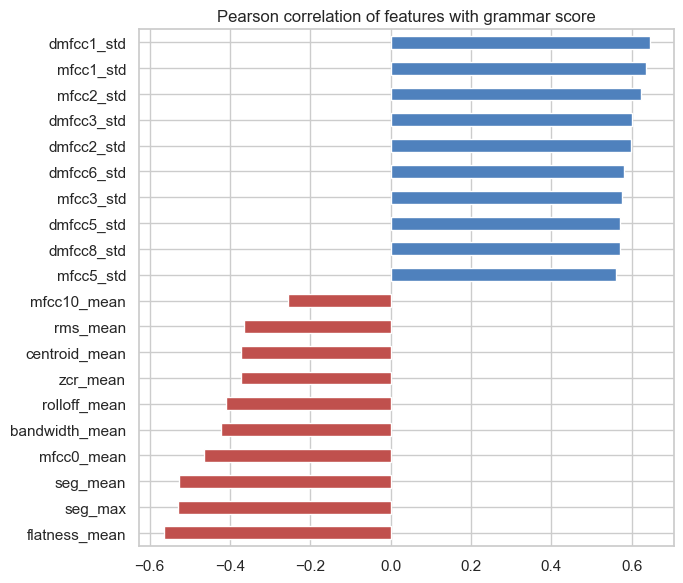

In [6]:
# Which interpretable features relate to the grammar score?
corr = F_audio[is_tr].corrwith(pd.Series(y, index=F_audio[is_tr].index)).dropna().sort_values()
top = pd.concat([corr.head(10), corr.tail(10)])
plt.figure(figsize=(7, 6)); top.plot(kind="barh", color=["#c0504d" if v < 0 else "#4f81bd" for v in top])
plt.title("Pearson correlation of features with grammar score"); plt.tight_layout(); plt.show()

In [7]:
FILLERS = {"um", "uh", "er", "erm", "ah", "hmm", "mm", "uhm", "umm", "uhh", "eh"}
SUBORD = {"because", "although", "though", "while", "whereas", "which", "that", "who", "if", "when", "since", "unless"}

def text_features(rec):
    """Cheap text/fluency features from a transcript record {'text', 'words': [[w, start, end, prob], ...], 'dur'}."""
    text, words, dur = rec["text"], rec["words"], max(rec["dur"], 1e-3)
    toks = [re.sub(r"[^a-z']", "", w[0].lower()) for w in words]
    toks = [t for t in toks if t]
    n = max(len(toks), 1)
    probs = np.array([w[3] for w in words]) if words else np.array([0.0])
    starts = np.array([w[1] for w in words]) if words else np.array([0.0])
    ends = np.array([w[2] for w in words]) if words else np.array([0.0])
    gaps = np.clip(starts[1:] - ends[:-1], 0, None) if len(words) > 1 else np.array([0.0])
    span = max(ends[-1] - starts[0], 1e-3)
    sents = [s for s in re.split(r"[.!?]+", text) if s.strip()]
    slen = [len(s.split()) for s in sents] or [0]
    return {"t_n_words": len(toks), "t_speech_rate": len(toks) / span, "t_pauses_05": int((gaps > 0.5).sum()),
            "t_filler_rate": sum(t in FILLERS for t in toks) / n,
            "t_repeats": sum(a == b for a, b in zip(toks[:-1], toks[1:])),
            "t_ttr": len(set(toks)) / n, "t_avg_word_len": np.mean([len(t) for t in toks]) if toks else 0,
            "t_n_sents": len(sents), "t_avg_sent_len": np.mean(slen), "t_max_sent_len": np.max(slen), "t_std_sent_len": np.std(slen),
            "t_conf_mean": probs.mean(), "t_conf_min": probs.min(), "t_low_conf": (probs < 0.5).mean(),
            "t_subord_rate": sum(t in SUBORD for t in toks) / n, "t_comma_rate": text.count(",") / n}

T_feats, T_emb = None, None
if USE_ASR:
    from faster_whisper import WhisperModel
    from sentence_transformers import SentenceTransformer
    asr = WhisperModel("tiny.en", device="cpu", compute_type="int8", cpu_threads=os.cpu_count() or 4)
    TR_PATH = os.path.join(CACHE_DIR, "transcripts_tiny.json")
    transcripts = json.load(open(TR_PATH)) if os.path.exists(TR_PATH) else {}
    PROMPT = "Umm, let me think, like, hmm... Okay, here's what I'm, uh, thinking."
    for i, p in enumerate(tqdm(all_df["path"], desc="Transcribing (tiny.en)")):
        key = os.path.basename(p)
        if key in transcripts: continue
        audio, _ = librosa.load(p, sr=16000, duration=ASR_SECONDS)
        segs, _ = asr.transcribe(audio, language="en", word_timestamps=True, beam_size=1,
                                 initial_prompt=PROMPT, condition_on_previous_text=False)
        text, words = [], []
        for s in segs:
            text.append(s.text.strip())
            words += [[w.word.strip(), float(w.start), float(w.end), float(w.probability)] for w in (s.words or [])]
        transcripts[key] = {"text": " ".join(text), "words": words, "dur": len(audio) / 16000}
        if i % 10 == 0: json.dump(transcripts, open(TR_PATH, "w"))   # resumable
    json.dump(transcripts, open(TR_PATH, "w"))
    recs = [transcripts[os.path.basename(p)] for p in all_df["path"]]
    T_feats = pd.DataFrame([text_features(r) for r in recs]).fillna(0)
    st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
    T_emb = st.encode([r["text"] for r in recs], batch_size=32, show_progress_bar=True, normalize_embeddings=True)
    print("Text features:", T_feats.shape, "| text embeddings:", T_emb.shape)
else:
    print("USE_ASR = False -> using acoustic/fluency features only (fastest).")

USE_ASR = False -> using acoustic/fluency features only (fastest).


In [8]:
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import pearsonr

blocks = {"audio": F_audio.values}
if USE_ASR:
    blocks["audio+textfeat"] = np.hstack([F_audio.values, T_feats.values])
    blocks["textemb"] = T_emb
    blocks["all"] = np.hstack([F_audio.values, T_feats.values, T_emb])

ridge = lambda lo, hi: (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(lo, hi, 15))))
models = {
    "Ridge | audio":  ("audio", ridge(1, 5)),
    "SVR | audio":    ("audio", lambda: make_pipeline(StandardScaler(), SVR(C=1.0, epsilon=0.2, gamma="scale"))),
    "GBM | audio":    ("audio", lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, l2_regularization=1.0, random_state=SEED)),
}
if USE_ASR:
    models.update({
        "Ridge | audio+textfeat": ("audio+textfeat", ridge(1, 5)),
        "Ridge | text emb":       ("textemb", ridge(0, 4)),
        "SVR | all":              ("all", lambda: make_pipeline(StandardScaler(), SVR(C=1.0, epsilon=0.2, gamma="scale"))),
    })

def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
clip = lambda p: np.clip(p, 0, 5)

kf = KFold(N_FOLDS, shuffle=True, random_state=SEED)
res = {}
for name, (blk, make) in models.items():
    Xall = blocks[blk]; Xtr, Xte = Xall[is_tr], Xall[~is_tr]
    oof, te = np.zeros(len(y)), np.zeros(len(Xte))
    for tr, va in kf.split(Xtr):
        m = make().fit(Xtr[tr], y[tr])
        oof[va] = m.predict(Xtr[va]); te += m.predict(Xte) / N_FOLDS
    full = make().fit(Xtr, y)                      # model refit on ALL training data
    trp = full.predict(Xtr)
    res[name] = {"oof": clip(oof), "test": clip(te), "train": clip(trp), "model": full, "blk": blk}
    print(f"{name:24s} CV RMSE={rmse(y, res[name]['oof']):.4f}  CV Pearson={pearsonr(y, res[name]['oof'])[0]:.4f}  Train RMSE={rmse(y, res[name]['train']):.4f}")

Ridge | audio            CV RMSE=0.8246  CV Pearson=0.7464  Train RMSE=0.7286
SVR | audio              CV RMSE=0.7490  CV Pearson=0.7967  Train RMSE=0.5271
GBM | audio              CV RMSE=0.7741  CV Pearson=0.7806  Train RMSE=0.4492


In [9]:
names = list(res)
S_oof   = np.column_stack([res[n]["oof"]   for n in names])
S_test  = np.column_stack([res[n]["test"]  for n in names])
S_train = np.column_stack([res[n]["train"] for n in names])
blender = LinearRegression(positive=True).fit(S_oof, y)
print("Blend weights:", dict(zip(names, np.round(blender.coef_, 3))), "| intercept:", round(float(blender.intercept_), 3))
blend_oof, blend_train, blend_test = clip(blender.predict(S_oof)), clip(blender.predict(S_train)), clip(blender.predict(S_test))

Blend weights: {'Ridge | audio': np.float64(0.0), 'SVR | audio': np.float64(0.698), 'GBM | audio': np.float64(0.343)} | intercept: -0.149


NameError: name 'results' is not defined

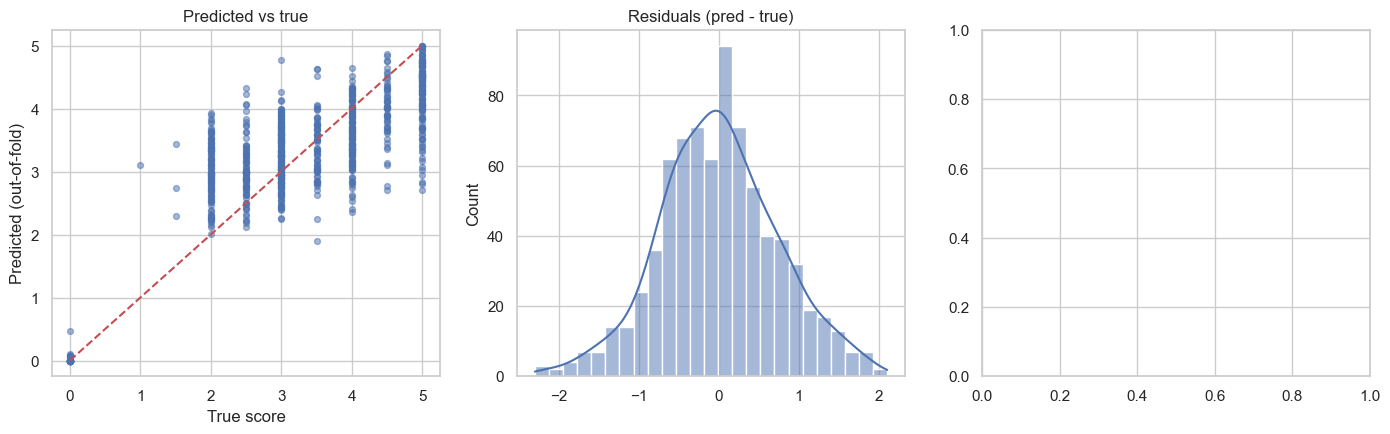

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(y, blend_oof, alpha=0.5, s=18); ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set_xlabel("True score"); ax[0].set_ylabel("Predicted (out-of-fold)"); ax[0].set_title("Predicted vs true")
sns.histplot(blend_oof - y, bins=25, kde=True, ax=ax[1]); ax[1].set_title("Residuals (pred - true)")
results["CV RMSE"].sort_values().plot(kind="barh", ax=ax[2], color="steelblue"); ax[2].set_title("CV RMSE by model (lower is better)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(x=np.round(y).astype(int), y=blend_oof); plt.xlabel("True score (rounded)"); plt.ylabel("Predicted")
plt.title("Predictions per true grade"); plt.show()

key = corr.abs().sort_values(ascending=False).index[:4]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, k in zip(ax, key):
    a.scatter(F_audio.loc[is_tr, k], y, alpha=0.4, s=14); a.set_xlabel(k); a.set_ylabel("score")
plt.tight_layout(); plt.show()

In [13]:
# ---- Align predictions with the ids used by the competition files ----
sub_label_col = sub.columns[-1]                        # prediction column of the sample file

def norm_key(s):
    """Normalise an id: drop folders and extension, trim spaces, lowercase ('A/b.WAV ' -> 'b')."""
    s = os.path.basename(str(s).strip().replace("\\", "/"))
    return os.path.splitext(s)[0].lower()

test_keys  = test[FILE_COL].map(norm_key)
train_keys = set(train[FILE_COL].map(norm_key))
pred_map   = dict(zip(test_keys, blend_test))          # predictions for every file in test.csv
wav_keys   = {norm_key(k): v for k, v in wav_index.items()}

cand_cols = list(sub.columns[:-1]) if len(sub.columns) > 1 else list(sub.columns)
id_col    = max(cand_cols, key=lambda c: sub[c].map(norm_key).isin(wav_keys).sum())
sub_keys  = sub[id_col].map(norm_key)

n_test  = int(sub_keys.isin(pred_map).sum())
n_train = int((~sub_keys.isin(pred_map) & sub_keys.isin(train_keys)).sum())
extra   = [k for k in sub_keys if k not in pred_map and k in wav_keys]          # audio exists, not in test.csv
missing = [k for k in sub_keys if k not in pred_map and k not in wav_keys]      # no audio available at all
print(f"sample_submission rows: {len(sub)} | test.csv rows: {len(test)} | wav files: {len(wav_keys)}")
print(f"  ids found in test.csv        : {n_test}")
print(f"  ids found in train.csv       : {n_train}")
print(f"  ids with audio, not in test  : {len(extra)} (will be predicted directly from the audio)")
print(f"  ids with NO audio anywhere   : {len(missing)} (filled with the training mean)")

def predict_new(paths):
    """Score audio files that were not part of test.csv, using the models refit on all training data."""
    if USE_ASR:
        raise RuntimeError("Scoring extra files needs USE_ASR = False (or transcribe them first).")
    rows = Parallel(n_jobs=N_JOBS)(delayed(audio_features)(p) for p in tqdm(paths, desc="Extra files"))
    Fn = pd.DataFrame(rows).reindex(columns=F_audio.columns).replace([np.inf, -np.inf], np.nan)
    Fn = Fn.fillna(F_audio.median())
    S = np.column_stack([clip(res[n]["model"].predict(Fn.values)) for n in names])
    return clip(blender.predict(S))

preds = dict(pred_map)
uniq_extra = sorted(set(extra))
if uniq_extra:
    for k, v in zip(uniq_extra, predict_new([wav_keys[k] for k in uniq_extra])):
        preds[k] = float(v)
for k in set(missing):
    preds[k] = float(np.mean(y))

# File 1 (main): every file in test.csv, in test.csv order  -> matches the "216 test samples" in the task
out_test = pd.DataFrame({id_col: test[FILE_COL].values, sub_label_col: blend_test})
out_test.to_csv("submission.csv", index=False)
# File 2: exactly the rows / order / ids of sample_submission.csv
out_sample = sub.copy()
out_sample[sub_label_col] = sub_keys.map(preds).values
out_sample.to_csv("submission_sample_format.csv", index=False)
print(f"\nSaved submission.csv ({len(out_test)} rows, test.csv order) and "
      f"submission_sample_format.csv ({len(out_sample)} rows, sample_submission.csv ids)")
assert out_test[sub_label_col].notna().all() and out_sample[sub_label_col].notna().all()
out_test.head()

sample_submission rows: 204 | test.csv rows: 216 | wav files: 773
  ids found in test.csv        : 25
  ids found in train.csv       : 80
  ids with audio, not in test  : 80 (will be predicted directly from the audio)
  ids with NO audio anywhere   : 99 (filled with the training mean)


Extra files: 100%|█████████████████████████████████████████████████████████████████████| 80/80 [00:19<00:00,  4.01it/s]



Saved submission.csv (216 rows, test.csv order) and submission_sample_format.csv (204 rows, sample_submission.csv ids)


,filename,label
0,audio_128.wav,2.855471
1,audio_156.wav,3.733729
2,audio_19.wav,3.634928
3,audio_108.wav,2.451411
4,audio_206.wav,4.975383
